# 02 — Análisis estadístico del riesgo crediticio

**Proyecto:** Credit Risk Scoring & Default Prediction  
**Fuente:** [UCI Default of Credit Card Clients (ID 350)](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)  
**Objetivo:** cuantificar incertidumbre y contrastar asociaciones entre variables históricas e incumplimiento (`DEFAULT`), sin confundir asociación con causalidad.

## Preguntas del análisis
1. ¿Cuál es la tasa general de incumplimiento y su intervalo de confianza?  
2. ¿Se asocia `PAY_0` con el incumplimiento? ¿Qué intensidad tiene la asociación?  
3. ¿Difieren las tasas entre clientes con `PAY_0 >= 2` y `PAY_0 <= 0`?  
4. ¿Difieren los límites de crédito y edades según incumplimiento?  
5. ¿Cómo corregimos por pruebas múltiples?

**Advertencias:** los datos son históricos (Taiwán, 2005), no sirven por sí solos para decisiones de crédito actuales. `PAY_0` usa códigos especiales `-2`, `-1` y `0`; se conservan sin redefinir su significado. Las variables demográficas se estudian para descripción/equidad, no para recomendar decisiones automáticas.

## 1. Preparación y dependencias

Si falta una librería, ejecuta la celda de instalación una sola vez y reinicia el kernel si Jupyter lo solicita.

In [1]:
%pip install -q pandas numpy scipy statsmodels matplotlib seaborn ucimlrepo openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from IPython.display import display

RANDOM_STATE = 42
ALPHA = 0.05
TARGET = "DEFAULT"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
for path in (RAW, PROCESSED, FIGURES):
    path.mkdir(parents=True, exist_ok=True)
print("Raíz del proyecto:", ROOT.resolve())

Raíz del proyecto: C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring


## 2. Carga robusta: compatible con Notebook 01

Se busca primero `data/processed/credit_risk_eda_base.csv` del Notebook 01, luego el CSV crudo y finalmente se intenta descargar UCI. El dataset de UCI puede venir como `X1`…`X23`: esta celda los renombra automáticamente. La variable objetivo será siempre `DEFAULT`. No dependemos de variables definidas en otro kernel.

In [3]:
processed_file = PROCESSED / "credit_risk_eda_base.csv"
raw_file = RAW / "default_credit_clients.csv"

if processed_file.exists():
    df = pd.read_csv(processed_file)
    source = str(processed_file)
elif raw_file.exists():
    df = pd.read_csv(raw_file)
    source = str(raw_file)
else:
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=350)
        df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
        source = "UCI (descarga online)"
    except Exception as exc:
        raise FileNotFoundError(
            "No encontré data/processed/credit_risk_eda_base.csv ni "
            "data/raw/default_credit_clients.csv y falló la descarga. "
            "Ejecuta y guarda el Notebook 01, o comprueba tu conexión a internet."
        ) from exc

mapping = {
    "X1":"LIMIT_BAL", "X2":"SEX", "X3":"EDUCATION", "X4":"MARRIAGE", "X5":"AGE",
    "X6":"PAY_0", "X7":"PAY_2", "X8":"PAY_3", "X9":"PAY_4", "X10":"PAY_5", "X11":"PAY_6",
    "X12":"BILL_AMT1", "X13":"BILL_AMT2", "X14":"BILL_AMT3", "X15":"BILL_AMT4",
    "X16":"BILL_AMT5", "X17":"BILL_AMT6", "X18":"PAY_AMT1", "X19":"PAY_AMT2",
    "X20":"PAY_AMT3", "X21":"PAY_AMT4", "X22":"PAY_AMT5", "X23":"PAY_AMT6",
    "default.payment.next.month":"DEFAULT"
}
df.columns = df.columns.astype(str).str.strip()
df = df.rename(columns=mapping)
required = ["DEFAULT", "PAY_0", "LIMIT_BAL", "AGE", "EDUCATION"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Faltan columnas {missing}. Columnas disponibles: {df.columns.tolist()}")
for col in required:
    df[col] = pd.to_numeric(df[col], errors="raise")
if df[required].isna().any().any():
    raise ValueError("Hay nulos en columnas requeridas; revísalos antes de probar hipótesis.")
if not df[TARGET].isin([0,1]).all():
    raise ValueError("DEFAULT debe contener exclusivamente 0 o 1")
print("Origen:", source)
print("Dimensiones:", df.shape)
print("Frecuencia de DEFAULT:", df[TARGET].value_counts().sort_index().to_dict())
display(df[required].head())

Origen: C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\data\processed\credit_risk_eda_base.csv
Dimensiones: (30000, 24)
Frecuencia de DEFAULT: {0: 23364, 1: 6636}


,DEFAULT,PAY_0,LIMIT_BAL,AGE,EDUCATION
0,1,2,20000,24,2
1,1,-1,120000,26,2
2,0,0,90000,34,2
3,0,0,50000,37,2
4,0,-1,50000,57,2


## 3. Conceptos y supuestos estadísticos

- **H₀:** ausencia de diferencia/asociación en la población; **H₁:** presencia de diferencia/asociación.
- **Valor p:** qué tan incompatibles son los datos con H₀ bajo supuestos del test. No es la probabilidad de que H₀ sea verdadera.
- **IC del 95 %:** incertidumbre del estimador bajo el procedimiento de muestreo y supuestos. Se usa Wilson para proporciones.
- **Tamaño del efecto:** importa además de la significancia, especialmente con 30,000 observaciones.
- **Independencia:** asumimos observaciones independientes; no está garantizada solo por el dataset. No hay diseño de muestreo documentado aquí.
- **Múltiples pruebas:** ajustamos los valores p exploratorios con Holm; sin un conjunto de hipótesis pre-registrado, son resultados exploratorios.
- **Asociación ≠ causalidad:** no se controlan confusores ni se establece temporalidad causal desde estas comparaciones.

## 4. Prevalencia del incumplimiento e IC de Wilson

Estimamos la proporción de clientes con `DEFAULT = 1` y su IC al 95 %. La proporción es una tasa histórica observada, no una probabilidad calibrada para nuevos clientes.

In [4]:
n_total = len(df)
n_default = int(df[TARGET].sum())
rate = n_default / n_total
lo, hi = proportion_confint(n_default, n_total, alpha=ALPHA, method="wilson")
summary_rate = pd.DataFrame([{"clientes":n_total, "incumplimientos":n_default,
                              "tasa_default_pct":100*rate, "IC95_inferior_pct":100*lo,
                              "IC95_superior_pct":100*hi}])
display(summary_rate)
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["Incumplimiento"], [100*rate], color="#3275a8")
ax.errorbar([0], [100*rate], yerr=[[100*(rate-lo)], [100*(hi-rate)]],
            fmt="none", capsize=7, color="black")
ax.set(ylabel="Porcentaje (%)", title="Incumplimiento histórico e IC de Wilson al 95 %")
ax.set_ylim(0, max(30, 100*hi*1.25))
plt.tight_layout(); plt.savefig(FIGURES / "02_prevalencia_wilson.png", dpi=140); plt.show()

,clientes,incumplimientos,tasa_default_pct,IC95_inferior_pct,IC95_superior_pct
0,30000,6636,22.1200,21.6539,22.5932


<Figure size 600x400 with 1 Axes>

## 5. Tasas de incumplimiento por `PAY_0`

Mostramos cada categoría tal como se registra, incluidos los códigos especiales. Los IC de Wilson reflejan que los segmentos pequeños tienen mayor incertidumbre.

,PAY_0,clientes,incumplen,tasa_pct,ic95_inf_pct,ic95_sup_pct
0,-2,2759,365,13.2294,12.0162,14.5450
1,-1,5686,954,16.7781,15.8293,17.7717
2,0,14737,1888,12.8113,12.2814,13.3606
3,1,3688,1252,33.9479,32.4371,35.4922
4,2,2667,1844,69.1414,67.3618,70.8658
5,3,322,244,75.7764,70.8107,80.1343
6,4,76,52,68.4211,57.3004,77.7691
7,5,26,13,50.0000,32.0606,67.9394
8,6,11,6,54.5455,28.0092,78.7287
9,7,9,7,77.7778,45.2589,93.6775


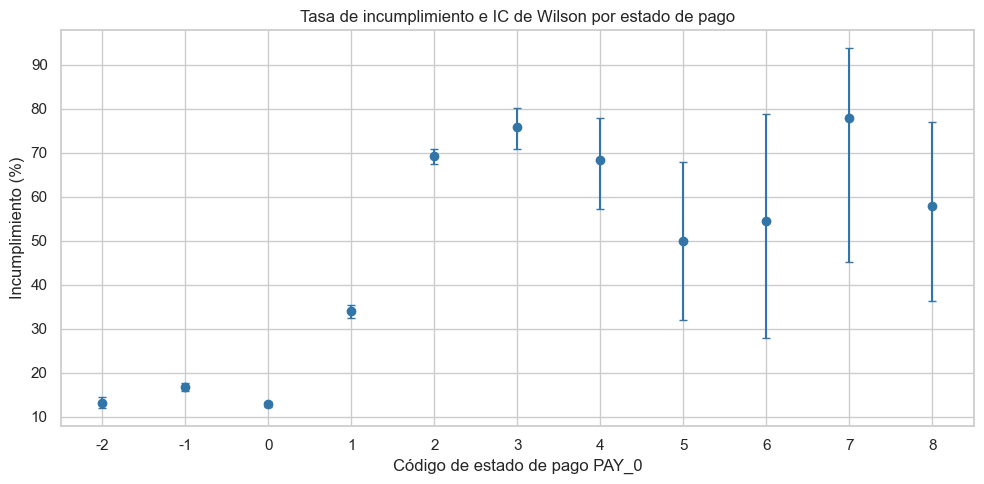

In [5]:
rows=[]
for status, g in df.groupby("PAY_0", dropna=False):
    count=len(g); events=int(g[TARGET].sum())
    lower,upper=proportion_confint(events,count,alpha=ALPHA,method="wilson")
    rows.append({"PAY_0":status,"clientes":count,"incumplen":events,
                 "tasa_pct":100*events/count,"ic95_inf_pct":100*lower,"ic95_sup_pct":100*upper})
risk_by_status=pd.DataFrame(rows).sort_values("PAY_0")
display(risk_by_status)
fig, ax=plt.subplots(figsize=(10,5))
ax.errorbar(risk_by_status["PAY_0"].astype(str), risk_by_status["tasa_pct"],
            yerr=[risk_by_status["tasa_pct"]-risk_by_status["ic95_inf_pct"],
                  risk_by_status["ic95_sup_pct"]-risk_by_status["tasa_pct"]],
            marker="o", capsize=3, linestyle="none", color="#3275a8")
ax.set(xlabel="Código de estado de pago PAY_0", ylabel="Incumplimiento (%)",
       title="Tasa de incumplimiento e IC de Wilson por estado de pago")
plt.tight_layout();plt.savefig(FIGURES / "02_riesgo_por_estado.png",dpi=140);plt.show()

## 6. Prueba chi-cuadrado e intensidad de asociación (V de Cramér)

**H₀:** `PAY_0` y `DEFAULT` son independientes. **H₁:** existe asociación. 

El test chi-cuadrado requiere revisar las frecuencias esperadas. V de Cramér varía de 0 (sin asociación) a 1 (asociación máxima); su interpretación depende del contexto y número de categorías.

In [6]:
def chi_square_result(data, feature, target=TARGET):
    table=pd.crosstab(data[feature],data[target],dropna=False)
    if table.shape[0]<2 or table.shape[1]<2:
        raise ValueError(f"La tabla para {feature} no tiene suficientes categorías")
    chi2,p,dof,expected=chi2_contingency(table, correction=False)
    n_obs=table.to_numpy().sum()
    cramers_v=np.sqrt((chi2/n_obs)/min(table.shape[0]-1,table.shape[1]-1))
    return {"variable":feature,"prueba":"chi-cuadrado", "estadistico":chi2,
            "p_sin_ajuste":p,"gl":dof,"V_Cramer":cramers_v,
            "esperadas_menor_5":int((expected<5).sum()),"celdas":int(expected.size)},table

chi_pay,table_pay=chi_square_result(df,"PAY_0")
display(table_pay)
display(pd.DataFrame([chi_pay]))
if chi_pay["esperadas_menor_5"]:
    print("Precaución: hay frecuencias esperadas <5; la aproximación chi-cuadrado puede ser inestable.")

DEFAULT,0,1
PAY_0,,
-2,2394,365
-1,4732,954
0,12849,1888
1,2436,1252
2,823,1844
3,78,244
4,24,52
5,13,13
6,5,6


,variable,prueba,estadistico,p_sin_ajuste,gl,V_Cramer,esperadas_menor_5,celdas
0,PAY_0,chi-cuadrado,"5,365.9650",0.0000,10,0.4229,3,22


Precaución: hay frecuencias esperadas <5; la aproximación chi-cuadrado puede ser inestable.


## 7. Comparación de dos tasas: estado de pago

**Contraste exploratorio predefinido:** `PAY_0 >= 2` frente a `PAY_0 <= 0`. Se excluye el código `1`; el grupo `<=0` incluye categorías especiales que **no deben etiquetarse automáticamente como sin atraso**. 

**H₀:** las dos proporciones de incumplimiento son iguales. **H₁:** difieren. Usamos un test z de dos proporciones y un IC de Newcombe para la diferencia de riesgos (grupo >=2 menos grupo <=0).

In [7]:
a = df.loc[df["PAY_0"] >= 2, TARGET]
b = df.loc[df["PAY_0"] <= 0, TARGET]
if len(a)==0 or len(b)==0:
    raise ValueError("No hay observaciones suficientes en ambos grupos")
count = np.array([int(a.sum()), int(b.sum())])
nobs = np.array([len(a),len(b)])
z,p_two = proportions_ztest(count,nobs,alternative="two-sided")
diff = count[0]/nobs[0] - count[1]/nobs[1]
ci_low,ci_high=confint_proportions_2indep(count1=count[0], nobs1=nobs[0],
                                          count2=count[1], nobs2=nobs[1],
                                          compare="diff",method="newcomb",alpha=ALPHA)
comparison=pd.DataFrame([{"grupo_1":"PAY_0 >= 2", "n_1":nobs[0], "tasa_1_pct":100*count[0]/nobs[0],
                          "grupo_2":"PAY_0 <= 0", "n_2":nobs[1], "tasa_2_pct":100*count[1]/nobs[1],
                          "dif_puntos_pct":100*diff,"IC95_inf_puntos":100*ci_low,
                          "IC95_sup_puntos":100*ci_high,"z":z,"p_sin_ajuste":p_two}])
display(comparison)
print("Observaciones PAY_0 == 1 excluidas:", int((df["PAY_0"]==1).sum()))

,grupo_1,n_1,tasa_1_pct,grupo_2,n_2,tasa_2_pct,dif_puntos_pct,IC95_inf_puntos,IC95_sup_puntos,z,p_sin_ajuste
0,PAY_0 >= 2,3130,69.5527,PAY_0 <= 0,23182,13.8340,55.7187,54.0225,57.3655,72.5286,0.0000


Observaciones PAY_0 == 1 excluidas: 3688


## 8. Variables numéricas: Mann–Whitney U y tamaño del efecto

Compararemos `LIMIT_BAL` y `AGE` por incumplimiento. Mann–Whitney examina diferencias en la distribución de rangos; **no es automáticamente una prueba de diferencias de medianas** si las distribuciones tienen formas distintas. El tamaño del efecto se expresa como correlación biserial de rangos `2U/(n1*n0) - 1` donde U corresponde a `DEFAULT=1`.

,variable,prueba,estadistico,p_sin_ajuste,mediana_default_1,mediana_default_0,dif_medianas,r_biserial_rangos
0,LIMIT_BAL,Mann-Whitney U,"59,257,217.5000",0.0000,"90,000.0000","150,000.0000","-60,000.0000",-0.2356
1,AGE,Mann-Whitney U,"78,076,624.5000",0.3725,34.0000,34.0000,0.0000,0.0072


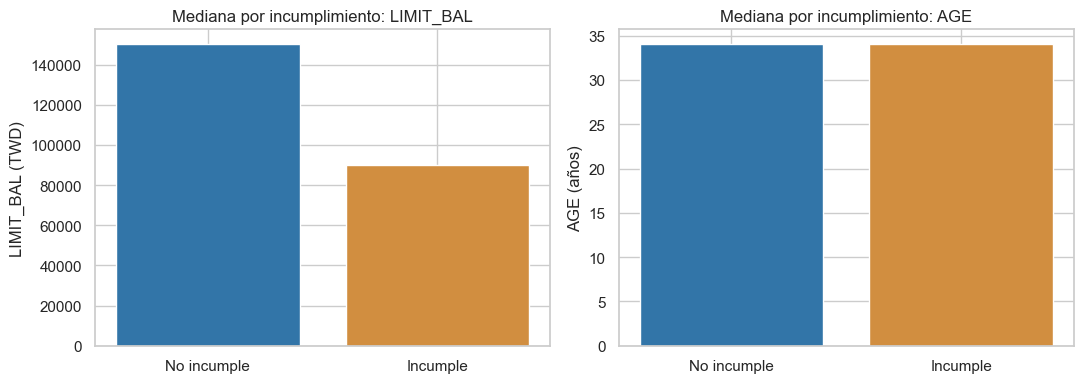

In [10]:
numerical_results=[]
for variable in ["LIMIT_BAL","AGE"]:
    g1=df.loc[df[TARGET]==1,variable].dropna().to_numpy()
    g0=df.loc[df[TARGET]==0,variable].dropna().to_numpy()
    u,p=mannwhitneyu(g1,g0,alternative="two-sided",method="asymptotic")
    rb=2*u/(len(g1)*len(g0))-1
    numerical_results.append({"variable":variable,"prueba":"Mann-Whitney U","estadistico":u,
                              "p_sin_ajuste":p,"mediana_default_1":float(np.median(g1)),
                              "mediana_default_0":float(np.median(g0)),
                              "dif_medianas":float(np.median(g1)-np.median(g0)),
                              "r_biserial_rangos":rb})
numerical_results=pd.DataFrame(numerical_results)
display(numerical_results)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,var in zip(axes,["LIMIT_BAL","AGE"]):
    meds=df.groupby(TARGET)[var].median().reindex([0,1])
    ax.bar(["No incumple","Incumple"], meds.values, color=["#3275a8","#d18e40"])
    ax.set(title=f"Mediana por incumplimiento: {var}",ylabel=f"{var} ({'TWD' if var=='LIMIT_BAL' else 'años'})")
plt.tight_layout()
plt.savefig(FIGURES/"02_medianas_por_default.png",dpi=140)
plt.show()

## 9. Otro contraste categórico: educación

`EDUCATION` tiene códigos no documentados en el dataset; se preservan por separado. Este contraste es descriptivo, **no justifica utilizar educación para aprobar o rechazar créditos**. Incluimos el test en la familia de pruebas que ajustaremos.

In [11]:
chi_education,table_education=chi_square_result(df,"EDUCATION")
display(table_education)
display(pd.DataFrame([chi_education]))
if chi_education["esperadas_menor_5"]:
    print("Precaución: hay celdas con frecuencia esperada <5 en EDUCATION; interpretar con reserva.")

DEFAULT,0,1
EDUCATION,,
0,14,0
1,8549,2036
2,10700,3330
3,3680,1237
4,116,7
5,262,18
6,43,8


,variable,prueba,estadistico,p_sin_ajuste,gl,V_Cramer,esperadas_menor_5,celdas
0,EDUCATION,chi-cuadrado,163.2166,0.0000,6,0.0738,1,14


Precaución: hay celdas con frecuencia esperada <5 en EDUCATION; interpretar con reserva.


## 10. Corrección por pruebas múltiples: Holm

Ajustamos conjuntamente 5 valores p: chi-cuadrado `PAY_0`, comparación de dos proporciones, Mann–Whitney para `LIMIT_BAL` y `AGE`, y chi-cuadrado `EDUCATION`. Se conservan estimadores y tamaños de efecto, no solo valores p.

In [12]:
hypotheses=[
    {"hipotesis":"PAY_0 vs DEFAULT","p":chi_pay["p_sin_ajuste"]},
    {"hipotesis":"PAY_0 >=2 vs <=0","p":p_two},
    {"hipotesis":"LIMIT_BAL vs DEFAULT","p":numerical_results.loc[numerical_results.variable=="LIMIT_BAL","p_sin_ajuste"].iloc[0]},
    {"hipotesis":"AGE vs DEFAULT","p":numerical_results.loc[numerical_results.variable=="AGE","p_sin_ajuste"].iloc[0]},
    {"hipotesis":"EDUCATION vs DEFAULT","p":chi_education["p_sin_ajuste"]},
]
hypothesis_results=pd.DataFrame(hypotheses)
rejected,p_adj,_,_=multipletests(hypothesis_results["p"],alpha=ALPHA,method="holm")
hypothesis_results["p_ajustado_holm"]=p_adj
hypothesis_results["rechazar_H0_05"]=rejected
display(hypothesis_results)
print("Nota: un p muy pequeño puede mostrarse como 0.0 por limitaciones numéricas; no significa probabilidad exactamente cero.")

,hipotesis,p,p_ajustado_holm,rechazar_H0_05
0,PAY_0 vs DEFAULT,0.0000,0.0000,True
1,PAY_0 >=2 vs <=0,0.0000,0.0000,True
2,LIMIT_BAL vs DEFAULT,0.0000,0.0000,True
3,AGE vs DEFAULT,0.3725,0.3725,False
4,EDUCATION vs DEFAULT,0.0000,0.0000,True


Nota: un p muy pequeño puede mostrarse como 0.0 por limitaciones numéricas; no significa probabilidad exactamente cero.


## 11. Conclusiones generadas desde los cálculos y exportación

Se imprimen resultados numéricos **solo después de ejecutarlos**. Las diferencias y asociaciones observadas no constituyen causalidad ni validación de un modelo de predicción. En Notebook 03 desarrollaremos features temporalmente coherentes, evitando fuga de información y ajustando transformaciones solo con entrenamiento.

In [13]:
decision = hypothesis_results.set_index("hipotesis")["rechazar_H0_05"]
print(f"Tasa de incumplimiento: {100*rate:.2f}% (IC Wilson 95%: {100*lo:.2f}–{100*hi:.2f}%).")
print(f"PAY_0 y DEFAULT: V de Cramér = {chi_pay['V_Cramer']:.3f}; asociación detectable tras Holm: {bool(decision['PAY_0 vs DEFAULT'])}.")
print(f"Diferencia de tasas (PAY_0 >=2 menos PAY_0 <=0): {100*diff:.2f} puntos porcentuales (IC 95%: {100*ci_low:.2f} a {100*ci_high:.2f}).")
for item in numerical_results.itertuples():
    print(f"{item.variable}: mediana DEFAULT=1 {item.mediana_default_1:,.1f}; mediana DEFAULT=0 {item.mediana_default_0:,.1f}; r biserial={item.r_biserial_rangos:.3f}.")

risk_by_status.to_csv(PROCESSED/"02_default_by_pay0_with_ci.csv",index=False)
summary_rate.to_csv(PROCESSED/"02_default_rate_with_ci.csv",index=False)
hypothesis_results.to_csv(PROCESSED/"02_hypothesis_tests_holm.csv",index=False)
numerical_results.to_csv(PROCESSED/"02_numeric_mann_whitney.csv",index=False)
comparison.to_csv(PROCESSED/"02_risk_difference_pay0.csv",index=False)
print("\nResultados guardados en:",PROCESSED)
print("Gráficos guardados en:",FIGURES)

Tasa de incumplimiento: 22.12% (IC Wilson 95%: 21.65–22.59%).
PAY_0 y DEFAULT: V de Cramér = 0.423; asociación detectable tras Holm: True.
Diferencia de tasas (PAY_0 >=2 menos PAY_0 <=0): 55.72 puntos porcentuales (IC 95%: 54.02 a 57.37).
LIMIT_BAL: mediana DEFAULT=1 90,000.0; mediana DEFAULT=0 150,000.0; r biserial=-0.236.
AGE: mediana DEFAULT=1 34.0; mediana DEFAULT=0 34.0; r biserial=0.007.

Resultados guardados en: C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\data\processed
Gráficos guardados en: C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\reports\figures
